In [1]:
import os
import numpy as np
from PIL import Image
import imageio.v3 as iio
import matplotlib.cm as cm
from matplotlib import pylab as plt


Load the training set into a matrix X: there are 540 training images in total, each has
50 × 50 pixels that need to be concatenated into a 2500-dimensional vector. So the size of X
should be 540 × 2500, where each row is a flattened face image. Pick a face image from X and
display that image in grayscale. Do the same thing for the test set. The size of matrix Xtest for
the test set should be 100 × 2500.

In [2]:
# Load training data
train_labels, train_data = [], []

for line in open('./faces/train.txt'):
    path, label = line.strip().split()
    im = iio.imread('./faces/' + path if not path.startswith('./faces/') else path)
    train_data.append(im.reshape(2500,))
    train_labels.append(int(label))

train_data = np.array(train_data, dtype=float)
train_labels = np.array(train_labels, dtype=int)

print(train_data.shape, train_labels.shape)

(540, 2500) (540,)


In [3]:
# Load test data
test_labels, test_data = [], []

for line in open('./faces/test.txt'):
    path, label = line.strip().split()
    im = iio.imread('./faces/' + path if not path.startswith('./faces/') else path)
    test_data.append(im.reshape(2500,))
    test_labels.append(int(label))

test_data = np.array(test_data, dtype=float)
test_labels = np.array(test_labels, dtype=int)

print(test_data.shape, test_labels.shape)

(100, 2500) (100,)


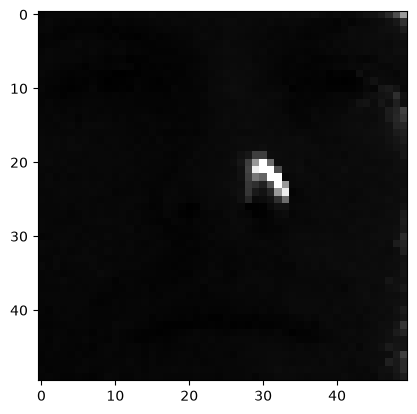

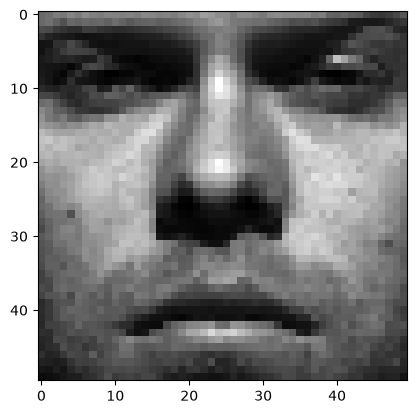

In [4]:
plt.imshow(train_data[0].reshape(50, 50), cmap=cm.gray)
plt.show()

plt.imshow(test_data[0].reshape(50, 50), cmap=cm.gray)
plt.show()

Average Face. Compute the average face μ from the whole training set by summing up
every row in X then dividing by the number of faces. Display the average face as a grayscale
image.

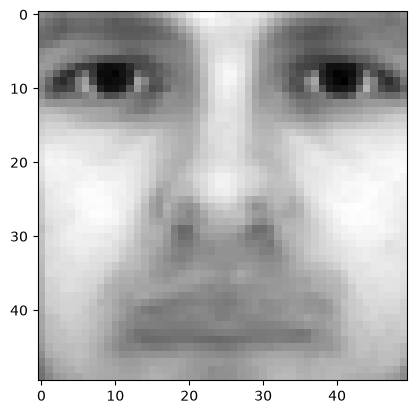

In [5]:
face_average = np.sum(train_data, axis=0) / train_data.shape[0]

plt.imshow(face_average.reshape(50, 50), cmap=cm.gray)
plt.show()

Mean Subtraction. Subtract average face μ from every row in X. That is, xi := xi −
μ, where xi is the i -th row of X. Pick a face image after mean subtraction from the new X
and display that image in grayscale. Do the same thing for the test set Xtest using the pre-
computed average face μ in (c).

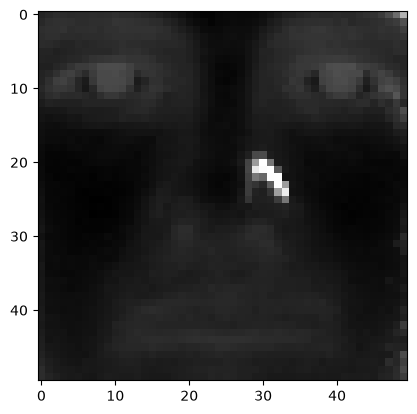

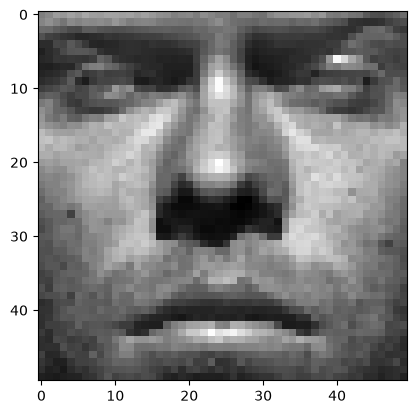

In [6]:
train_data = train_data - face_average
test_data = test_data - face_average

plt.imshow(train_data[0].reshape(50, 50), cmap=cm.gray)
plt.show()

plt.imshow(test_data[0].reshape(50, 50), cmap=cm.gray)
plt.show()

Eigenface. Perform eigendecomposition on XT X = VΛVT to get eigenvectors VT ,
where each row of VT has the same dimension as the face image. We refer to vi, the i -th
row of VT , as i -th eigenface. Display the first 10 eigenfaces as 10 images in grayscale.

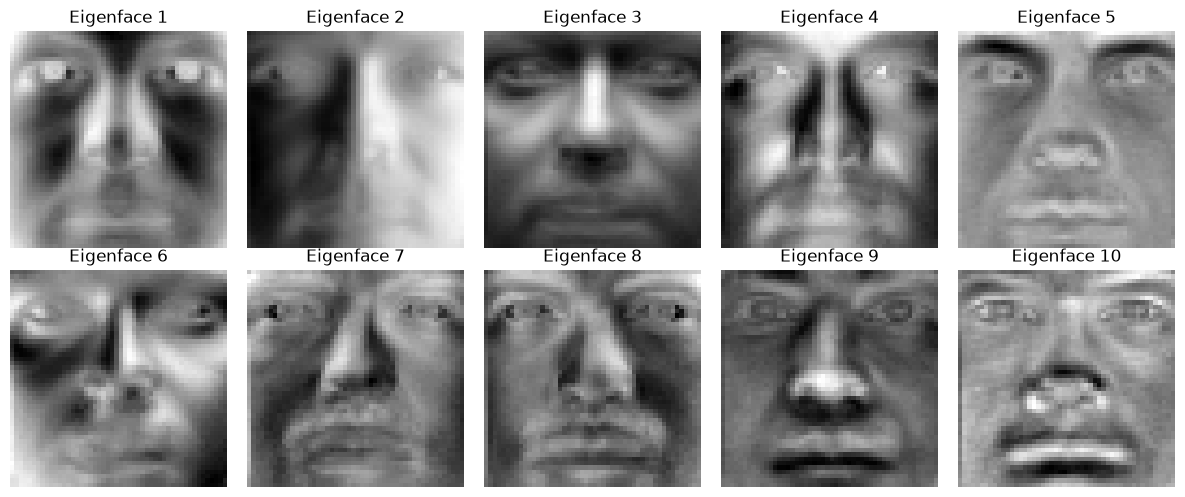

In [7]:
# Eigendecomposition of X.T @ X
eigenvalues, eigenvectors = np.linalg.eigh(train_data.T @ train_data)

# Sort eigenfaces by descending eigenvalue
idx = np.argsort(eigenvalues)[::-1]
eigenvectors = eigenvectors[:, idx]

# Display the first 10 eigenfaces
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(eigenvectors[:, i].reshape(50, 50), cmap=cm.gray)
    plt.title(f"Eigenface {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Eigenface Feature. The top r eigenfaces VT [: r, :] = {v1, v2, . . . , vr }T span an r -dimensional
linear subspace of the original image space called face space, whose origin is the average face
μ, and whose axes are the eigenfaces {v1, v2, . . . , vr }. Therefore, using the top r eigenfaces
{v1, v2, . . . , vr }, we can represent a 2500-dimensional face image z as an r -dimensional fea-
ture vector f: f = VT [: r, :] z = [v1, v2, . . . , vr ]T z. Write a function to generate r -dimensional
feature matrix F and Ftest for training images X and test images Xtest, respectively (to get F,
multiply X to the transpose of first r rows of VT , F should have same number of rows as X and
r columns; similarly for Xtest)

In [8]:
r =  eigenvectors.shape[1]  # choose the number of eigenfaces

VT = eigenvectors.T

F = train_data @ VT[:r, :].T
Ftest = test_data @ VT[:r, :].T

print(F.shape)
print(Ftest.shape)

(540, 2500)
(100, 2500)


Face Recognition. For this problem, you are welcome to use libraries such as scikit
learn to perform logistic regression. Extract training and test features for r = 10. Train a
Logistic Regression model using F and test on Ftest. Report the classification accuracy on the
test set. Plot the classification accuracy on the test set as a function of r when r = 1, 2, . . . , 200.
Use “one-vs-rest” logistic regression, where a classifier is trained for each possible output
label. Each classifier is trained on faces with that label as positive data and all faces with
other labels as negative data. sklearn calls this the “ovr” mode.

Test accuracy for r = 10: 0.8


c:\Users\Asus\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Asus\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproces

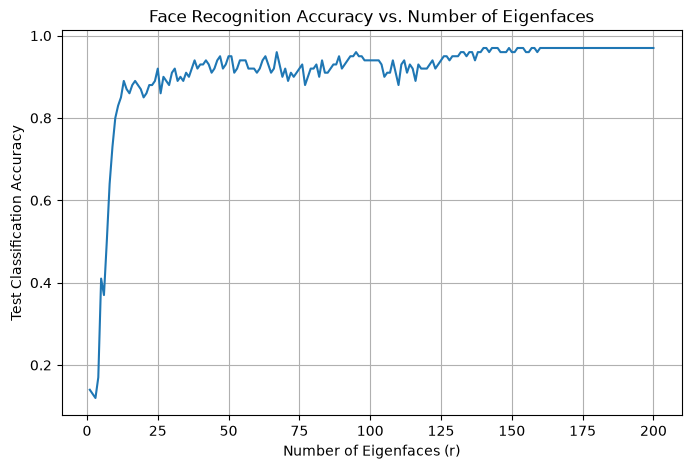

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score

# Eigenvectors are sorted by descending eigenvalue
VT = eigenvectors.T

# Train and test labels should already be loaded
y_train = train_labels
y_test = test_labels

# Extract features for r = 10
r = 10
F = train_data @ VT[:r, :].T
Ftest = test_data @ VT[:r, :].T

# Train one-vs-rest logistic regression
model = OneVsRestClassifier(
    LogisticRegression(max_iter=2000)
)
model.fit(F, y_train)

# Evaluate test accuracy
predictions = model.predict(Ftest)
accuracy = accuracy_score(y_test, predictions)

print("Test accuracy for r = 10:", accuracy)

# Test accuracy for r = 1, 2, ..., 200
accuracies = []

for r in range(1, 201):
    F = train_data @ VT[:r, :].T
    Ftest = test_data @ VT[:r, :].T

    model = OneVsRestClassifier(
        LogisticRegression(max_iter=2000)
    )
    model.fit(F, y_train)

    predictions = model.predict(Ftest)
    accuracies.append(accuracy_score(y_test, predictions))

# Plot accuracy against number of eigenfaces
plt.figure(figsize=(8, 5))
plt.plot(range(1, 201), accuracies)
plt.xlabel("Number of Eigenfaces (r)")
plt.ylabel("Test Classification Accuracy")
plt.title("Face Recognition Accuracy vs. Number of Eigenfaces")
plt.grid(True)
plt.show()

Low-Rank Data Loss. These feature matrices F can be mapped back to their original
dimensions; however, information is lost in the process and only approximations X′ will be
recovered. This is done by multiplying the feature matrices F once again by the first r rows of
VT . Plot the Frobenius distance d(X, X′) =√︂ tr(︁ (X − X′)T (X − X′))︁ between the original data X
and their approximations X′, over r = 1, 2, ..., 200

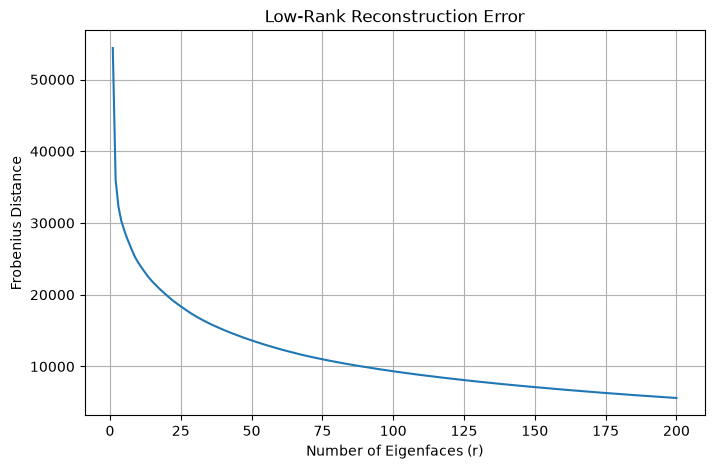

In [74]:
distances = []

VT = eigenvectors.T

for r in range(1, 201):
    F = train_data @ VT[:r, :].T
    X_approx = F @ VT[:r, :]

    d = np.linalg.norm(train_data - X_approx, ord='fro')
    distances.append(d)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 201), distances)
plt.xlabel("Number of Eigenfaces (r)")
plt.ylabel("Frobenius Distance")
plt.title("Low-Rank Reconstruction Error")
plt.grid(True)
plt.show()

#### Random Forests for Image Approximation

Start with an image of the Mona Lisa. If you don’t like the Mona Lisa, pick another
interesting image of your choice. Read and display the image.

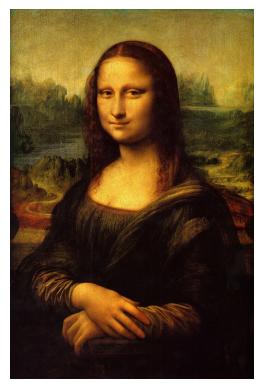

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

image = Image.open("Mona_Lisa.jpg")

plt.imshow(image)
plt.axis('off')
plt.show()

Data Preprocessing

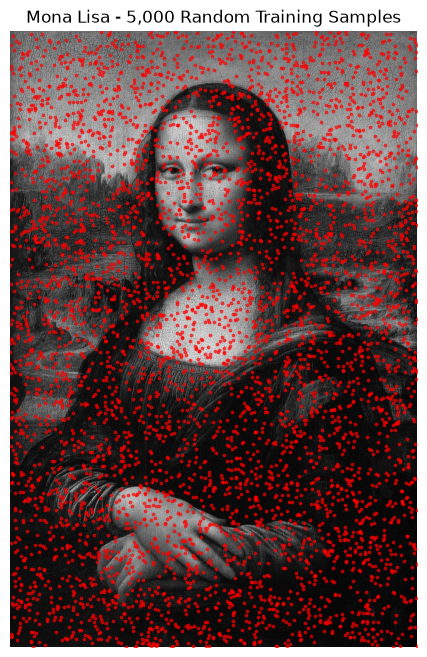

Image dimensions (width, height): (960, 1452)
X_train shape: (5000, 2)
y_train shape: (5000,)
Normalized target range: (np.float32(0.007843138), np.float32(0.89411765))


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO



# 2. Convert to grayscale
gray_image = image.convert("L")

# 3. Convert to a NumPy array and normalize pixel values
pixel_values = np.asarray(gray_image, dtype=np.float32) / 255.0

# 4. Get image dimensions
height, width = pixel_values.shape

# 5. Sample 5,000 unique pixel coordinates uniformly
rng = np.random.default_rng(42)
pixel_indices = rng.choice(height * width, size=5000, replace=False)

y_coords, x_coords = np.unravel_index(pixel_indices, (height, width))

# 6. Create training features and target values
X_train = np.column_stack((x_coords, y_coords))
y_train = pixel_values[y_coords, x_coords]

# 7. Display image with sampled points
plt.figure(figsize=(7, 8))
plt.imshow(pixel_values, cmap="gray", vmin=0, vmax=1)
plt.scatter(x_coords, y_coords, s=3, c="red", alpha=0.6)
plt.title("Mona Lisa - 5,000 Random Training Samples")
plt.axis("off")
plt.show()

# 8. Verify the training dataset
print("Image dimensions (width, height):", (width, height))
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Normalized target range:", (y_train.min(), y_train.max()))

Approximation using Random Forest

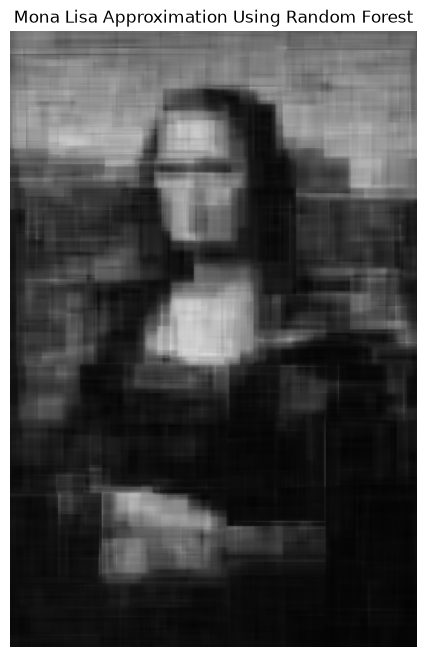

In [8]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import matplotlib.pyplot as plt

# 1. Train the random forest
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# 2. Generate coordinates for every pixel
height, width = pixel_values.shape

xx, yy = np.meshgrid(np.arange(width), np.arange(height))
X_test = np.column_stack((xx.ravel(), yy.ravel()))

# 3. Predict brightness for every pixel
y_pred = rf.predict(X_test)

# 4. Reshape predictions into the original image dimensions
approx_image = y_pred.reshape(height, width)

# 5. Display the reconstructed image
plt.figure(figsize=(7, 8))
plt.imshow(approx_image, cmap="gray", vmin=0, vmax=1)
plt.title("Mona Lisa Approximation Using Random Forest")
plt.axis("off")
plt.show()

Depth Changes [1, 2, 3, 5, 10, 15]

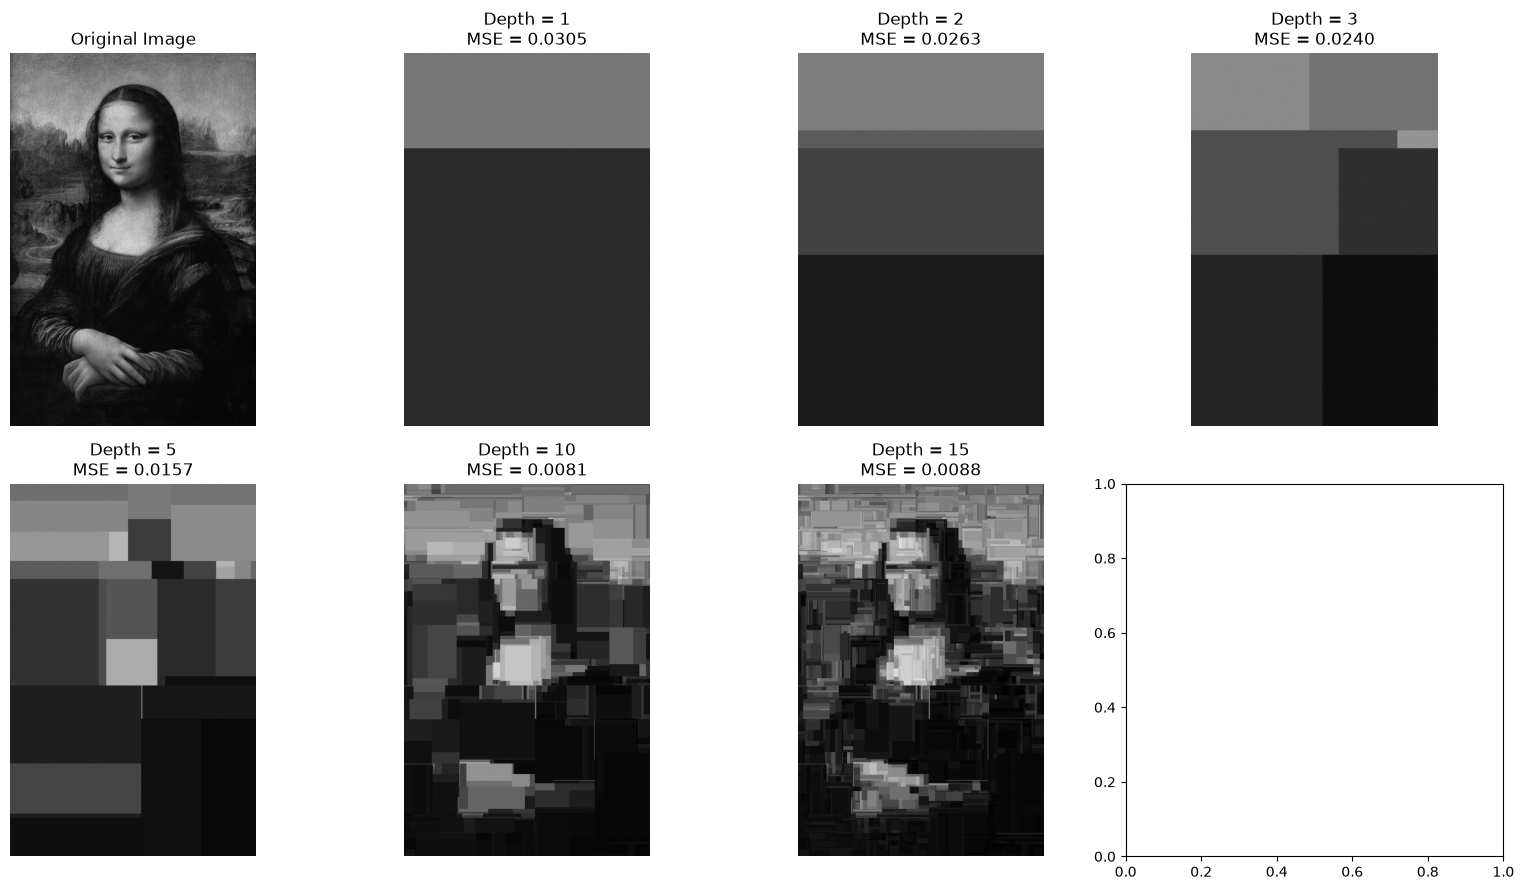

Depth     Leaves      Reconstruction MSE  
1         2           0.030549            
2         4           0.026299            
3         8           0.024007            
5         32          0.015722            
10        676         0.008053            
15        3078        0.008777            


In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Generate coordinates for every pixel in the image
height, width = pixel_values.shape

xx, yy = np.meshgrid(np.arange(width), np.arange(height))
X_test = np.column_stack((xx.ravel(), yy.ravel()))

# Tree depths to compare
depths = [1, 2, 3, 5, 10, 15]

# Display the original and reconstructed images
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.ravel()

# Original image
axes[0].imshow(pixel_values, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Image")
axes[0].axis("off")

results = []

for i, depth in enumerate(depths):
    # Create a single decision tree with the specified maximum depth
    tree = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Train on the same 5,000 samples
    tree.fit(X_train, y_train)

    # Predict the brightness of every pixel
    predictions = tree.predict(X_test)
    reconstructed = predictions.reshape(height, width)

    # Calculate reconstruction error against the original image
    mse = mean_squared_error(
        pixel_values.ravel(),
        predictions
    )

    results.append((depth, tree.get_n_leaves(), mse))

    # Display reconstruction
    axes[i + 1].imshow(
        reconstructed,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i + 1].set_title(f"Depth = {depth}\nMSE = {mse:.4f}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

# Print quantitative comparison
print(f"{'Depth':<10}{'Leaves':<12}{'Reconstruction MSE':<20}")
for depth, leaves, mse in results:
    print(f"{depth:<10}{leaves:<12}{mse:<20.6f}")

Depth Changes [1, 3, 5, 10, 100]

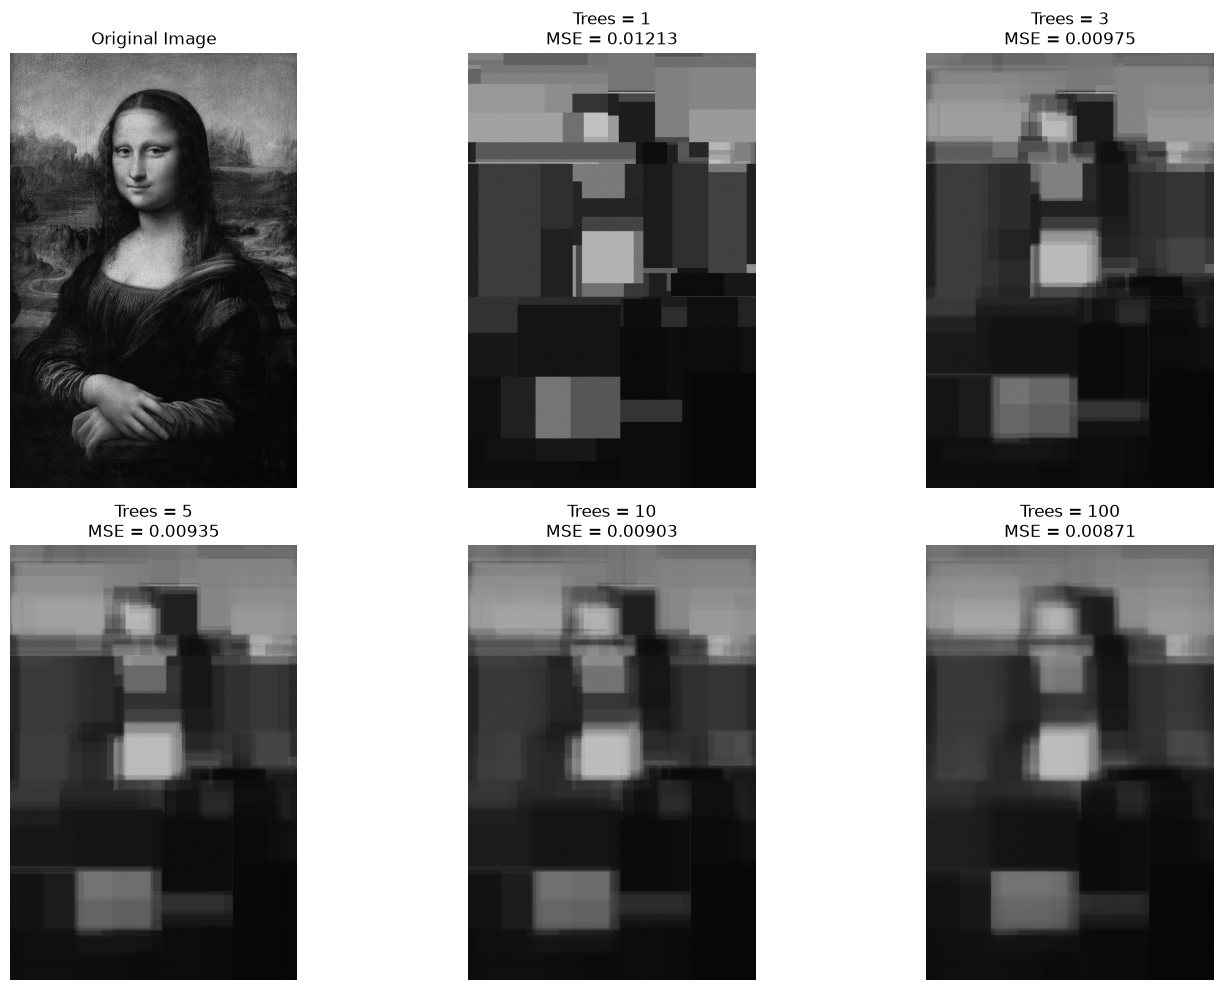

Number of trees     Reconstruction MSE  
1                   0.012129            
3                   0.009745            
5                   0.009346            
10                  0.009028            
100                 0.008714            


In [10]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Use the same test coordinates and original image
height, width = pixel_values.shape

xx, yy = np.meshgrid(np.arange(width), np.arange(height))
X_test = np.column_stack((xx.ravel(), yy.ravel()))

# Number of trees to compare
tree_counts = [1, 3, 5, 10, 100]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

# Display the original image
axes[0].imshow(pixel_values, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Image")
axes[0].axis("off")

results = []

for i, n_trees in enumerate(tree_counts):
    # Fix depth at 7 and vary only the number of trees
    rf = RandomForestRegressor(
        n_estimators=n_trees,
        max_depth=7,
        random_state=42,
        n_jobs=-1
    )

    # Train using the existing 5,000 samples
    rf.fit(X_train, y_train)

    # Predict all pixel intensities
    predictions = rf.predict(X_test)
    reconstructed = predictions.reshape(height, width)

    # Measure reconstruction error against the original image
    mse = mean_squared_error(pixel_values.ravel(), predictions)

    results.append((n_trees, mse))

    axes[i + 1].imshow(
        reconstructed, cmap="gray", vmin=0, vmax=1
    )
    axes[i + 1].set_title(f"Trees = {n_trees}\nMSE = {mse:.5f}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

# Print results for comparison
print(f"{'Number of trees':<20}{'Reconstruction MSE':<20}")
for n_trees, mse in results:
    print(f"{n_trees:<20}{mse:<20.6f}")


Mona Lisa 1-NN Comparison

k-NN (k=1) reconstruction MSE: 0.007940


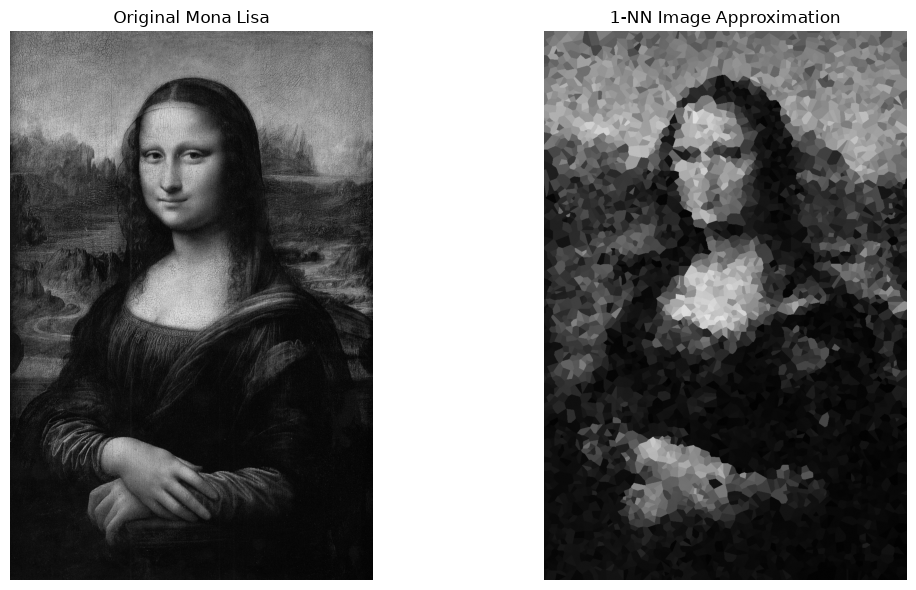

In [11]:

from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Get original image dimensions
height, width = pixel_values.shape

# 1. Create the k-NN regressor with k = 1
knn = KNeighborsRegressor(
    n_neighbors=1,
    metric="euclidean",
    n_jobs=-1
)

# 2. Fit using the 5,000 sampled training coordinates
knn.fit(X_train, y_train)

# 3. Generate coordinates for every pixel
xx, yy = np.meshgrid(np.arange(width), np.arange(height))
X_test = np.column_stack((xx.ravel(), yy.ravel()))

# 4. Predict in batches to limit memory usage
predictions = np.empty(X_test.shape[0], dtype=np.float32)

batch_size = 20000

for start in range(0, len(X_test), batch_size):
    end = min(start + batch_size, len(X_test))
    predictions[start:end] = knn.predict(X_test[start:end])

# 5. Reconstruct the image
knn_image = predictions.reshape(height, width)

# 6. Calculate reconstruction error
mse = mean_squared_error(pixel_values.ravel(), predictions)
print(f"k-NN (k=1) reconstruction MSE: {mse:.6f}")

# 7. Display the original and reconstructed images
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(pixel_values, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Mona Lisa")
axes[0].axis("off")

axes[1].imshow(knn_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("1-NN Image Approximation")
axes[1].axis("off")

plt.tight_layout()
plt.show()


Different Pruning Strategies

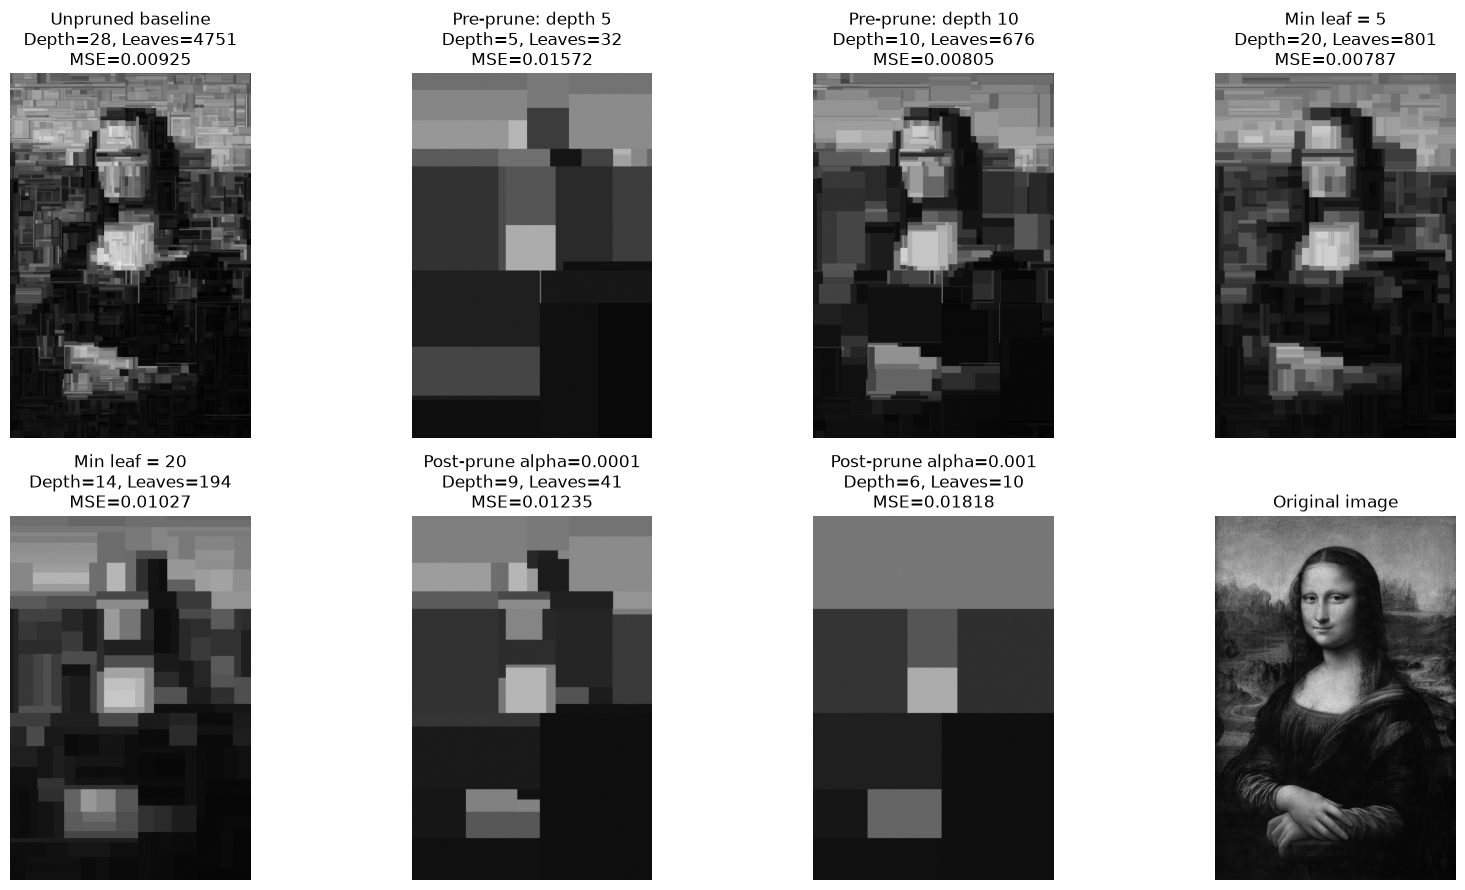

Model                          Depth   Leaves          MSE
Unpruned baseline                 28     4751     0.009252
Pre-prune: depth 5                 5       32     0.015722
Pre-prune: depth 10               10      676     0.008053
Min leaf = 5                      20      801     0.007869
Min leaf = 20                     14      194     0.010272
Post-prune alpha=0.0001            9       41     0.012345
Post-prune alpha=0.001             6       10     0.018179


In [12]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

height, width = pixel_values.shape

# All pixel coordinates for reconstruction
xx, yy = np.meshgrid(np.arange(width), np.arange(height))
X_test = np.column_stack((xx.ravel(), yy.ravel()))

# Experiment configurations
configs = [
    ("Unpruned baseline", {}),
    ("Pre-prune: depth 5", {"max_depth": 5}),
    ("Pre-prune: depth 10", {"max_depth": 10}),
    ("Min leaf = 5", {"min_samples_leaf": 5}),
    ("Min leaf = 20", {"min_samples_leaf": 20}),
    ("Post-prune alpha=0.0001", {"ccp_alpha": 0.0001}),
    ("Post-prune alpha=0.001", {"ccp_alpha": 0.001}),
]

results = []
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
axes = axes.ravel()

for i, (name, params) in enumerate(configs):
    tree = DecisionTreeRegressor(random_state=42, **params)
    tree.fit(X_train, y_train)

    pred = tree.predict(X_test)
    reconstructed = pred.reshape(height, width)
    mse = mean_squared_error(pixel_values.ravel(), pred)

    results.append({
        "name": name,
        "mse": mse,
        "depth": tree.get_depth(),
        "leaves": tree.get_n_leaves()
    })

    axes[i].imshow(reconstructed, cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(
        f"{name}\nDepth={tree.get_depth()}, "
        f"Leaves={tree.get_n_leaves()}\nMSE={mse:.5f}"
    )
    axes[i].axis("off")

# Original image in the last panel
axes[7].imshow(pixel_values, cmap="gray", vmin=0, vmax=1)
axes[7].set_title("Original image")
axes[7].axis("off")

plt.tight_layout()
plt.show()

print(f"{'Model':<28} {'Depth':>7} {'Leaves':>8} {'MSE':>12}")
for r in results:
    print(
        f"{r['name']:<28} {r['depth']:>7} "
        f"{r['leaves']:>8} {r['mse']:>12.6f}"
    )
